In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# This is the hourly AQS NO2 file.
# 42602 is the AQS parameter code for NO2.
epa_file = Path("hourly_42602_2023.csv")

start_dt = pd.Timestamp("2023-07-01 00:00")
end_dt   = pd.Timestamp("2023-07-31 23:00")

In [3]:
# low_memory=False keeps pandas from guessing column types in chunks.
# This helps avoid weird dtype warnings when reading large EPA files.
no2 = pd.read_csv(epa_file, low_memory=False)

# I like replacing underscores with spaces because that matches the column
# names I usually expect when working with AQS data.
no2.columns = [c.replace("_", " ") for c in no2.columns]

print("Rows loaded:", len(no2))
print("Columns in file:")
print(no2.columns.tolist())

Rows loaded: 3595761
Columns in file:
['State Code', 'County Code', 'Site Num', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Date Local', 'Time Local', 'Date GMT', 'Time GMT', 'Sample Measurement', 'Units of Measure', 'MDL', 'Uncertainty', 'Qualifier', 'Method Type', 'Method Code', 'Method Name', 'State Name', 'County Name', 'Date of Last Change']


In [6]:
# AQS files usually store date and time separately in GMT.
no2["Datetime GMT"] = pd.to_datetime(
    no2["Date GMT"] + " " + no2["Time GMT"],
    errors="coerce"
)

# Keep only July 2023.
no2_july = no2[
    (no2["Datetime GMT"] >= start_dt) &
    (no2["Datetime GMT"] <= end_dt)
].copy()

print("Rows in July:", len(no2_july))
print("Date range:", no2_july["Datetime GMT"].min(), "to", no2_july["Datetime GMT"].max())

Rows in July: 304022
Date range: 2023-07-01 00:00:00 to 2023-07-31 23:00:00


In [7]:
# First I want to know if there are missing values in the columns I need.
qaqc_cols = [
    "Datetime GMT",
    "Sample Measurement",
    "Units of Measure",
    "Latitude",
    "Longitude",
    "State Code",
    "County Code",
    "Site Num",
]

print("\nMissing values in key columns:")
print(no2_july[qaqc_cols].isna().sum())

# Check the reported units.
print("\nUnits in file:")
print(no2_july["Units of Measure"].value_counts(dropna=False))

# Convert ppm to ppb if needed so everything is easier to interpret.
# NO2 is usually discussed in ppb.
no2_july["NO2_ppb"] = no2_july["Sample Measurement"]

ppm_mask = no2_july["Units of Measure"].str.contains("Parts per million", na=False)
no2_july.loc[ppm_mask, "NO2_ppb"] = no2_july.loc[ppm_mask, "Sample Measurement"] * 1000

# Flag values that look suspicious.
# I am not deleting these yet; I just want to see what might need review.
no2_july["flag_negative"] = no2_july["NO2_ppb"] < 0
no2_july["flag_high"] = no2_july["NO2_ppb"] > 200

print("\nQAQC flags:")
print("Negative NO2 values:", no2_july["flag_negative"].sum())
print("NO2 values > 200 ppb:", no2_july["flag_high"].sum())

# For plotting, remove missing, negative, and very high values.
# This keeps the plot readable while preserving the original dataframe above.
no2_clean = no2_july[
    no2_july["NO2_ppb"].notna() &
    (~no2_july["flag_negative"]) &
    (~no2_july["flag_high"])
].copy()

print("\nRows after basic QAQC:", len(no2_clean))



Missing values in key columns:
Datetime GMT          0
Sample Measurement    0
Units of Measure      0
Latitude              0
Longitude             0
State Code            0
County Code           0
Site Num              0
dtype: int64

Units in file:
Parts per billion    304022
Name: Units of Measure, dtype: int64

QAQC flags:
Negative NO2 values: 3762
NO2 values > 200 ppb: 0

Rows after basic QAQC: 300260


In [8]:
# Create a monitor ID so each site is easier to track.
no2_clean["monitor_id"] = (
    no2_clean["State Code"].astype(str).str.zfill(2) + "-" +
    no2_clean["County Code"].astype(str).str.zfill(3) + "-" +
    no2_clean["Site Num"].astype(str).str.zfill(4)
)

monitor_summary = (
    no2_clean
    .groupby(["monitor_id", "Latitude", "Longitude"], as_index=False)
    .agg(
        n_hours=("NO2_ppb", "count"),
        mean_no2=("NO2_ppb", "mean"),
        max_no2=("NO2_ppb", "max")
    )
    .sort_values("n_hours", ascending=False)
)

print("\nMonitor summary:")
display(monitor_summary)


Monitor summary:


,monitor_id,Latitude,Longitude,n_hours,mean_no2,max_no2
63,06-065-8001,33.999580,-117.416010,1488,9.807191,44.9
42,06-037-1103,34.066590,-118.226880,1482,13.264035,48.0
377,49-011-0004,40.902967,-111.884467,1473,5.779362,35.7
383,49-035-3006,40.736389,-111.872222,1473,4.931161,23.3
211,27-003-1002,45.137680,-93.207615,1457,5.050652,27.0
...,...,...,...,...,...,...
351,48-201-1050,29.583047,-95.015544,99,2.297980,6.8
17,06-001-0013,37.864767,-122.302741,94,6.744681,17.3
91,06-083-1013,34.725352,-120.428717,83,0.220482,2.1
115,08-067-1004,37.303890,-107.484167,73,0.267123,1.1


In [9]:
# Define a rough Chicago-area spatial box.
# This is intentionally simple for a teaching example.
lat_min, lat_max = 41.0, 42.5
lon_min, lon_max = -88.6, -87.0

no2_chicago = no2_clean[
    (no2_clean["Latitude"] >= lat_min) &
    (no2_clean["Latitude"] <= lat_max) &
    (no2_clean["Longitude"] >= lon_min) &
    (no2_clean["Longitude"] <= lon_max)
].copy()

print("Rows near Chicago:", len(no2_chicago))
print("Number of monitors near Chicago:", no2_chicago["monitor_id"].nunique())

Rows near Chicago: 3850
Number of monitors near Chicago: 7


In [10]:
# This gives one average NO2 value per monitor for all of July.
monitor_july_mean = (
    no2_chicago
    .groupby(["monitor_id", "Latitude", "Longitude"], as_index=False)
    .agg(
        mean_no2_july=("NO2_ppb", "mean"),
        n_obs=("NO2_ppb", "count")
    )
)

display(monitor_july_mean)

,monitor_id,Latitude,Longitude,mean_no2_july,n_obs
0,17-031-0076,41.751400,-87.713488,13.294142,239
1,17-031-0119,41.578620,-87.557406,17.677285,744
2,17-031-0219,41.920009,-87.672995,19.103491,487
3,17-031-3103,41.965193,-87.876265,17.257739,743
4,17-031-4002,41.855243,-87.752470,12.998092,262
5,17-031-4201,42.139996,-87.799227,8.410068,735
6,18-089-0022,41.606662,-87.304943,9.717812,640


<h1> Lets plot these spatially. 

In [14]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature  
# When downloading these modules, be careful when updating supporting packages
# Spatial python packages are notorious and can mess up your entire envirnonment by changing the 
# previously downloaded packages version types for example.
# I typically make a new environment for each of my mapping packages. Hard lesson learned. :) 

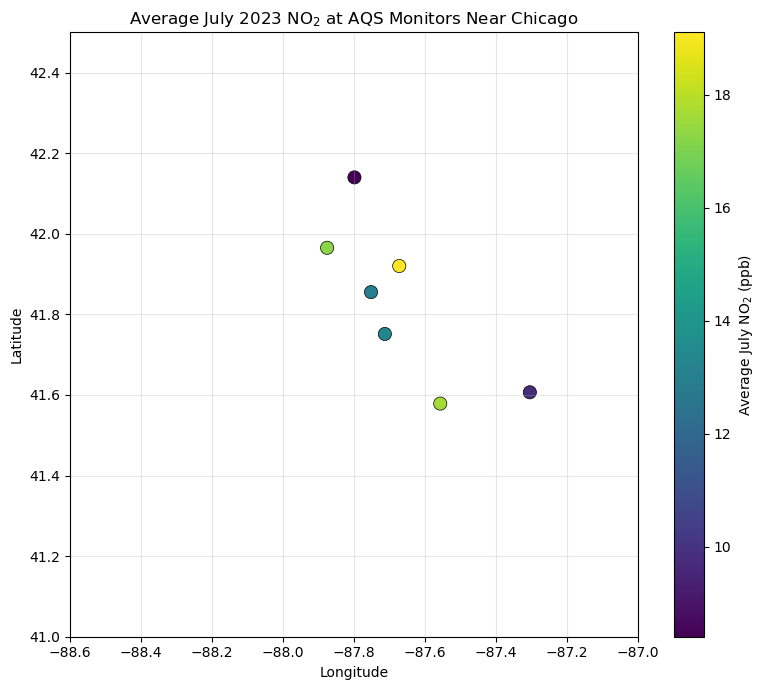

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))

sc = ax.scatter(
    monitor_july_mean["Longitude"],
    monitor_july_mean["Latitude"],
    c=monitor_july_mean["mean_no2_july"],
    s=90,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.5
)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Average July NO$_2$ (ppb)")

ax.set_title("Average July 2023 NO$_2$ at AQS Monitors Near Chicago")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

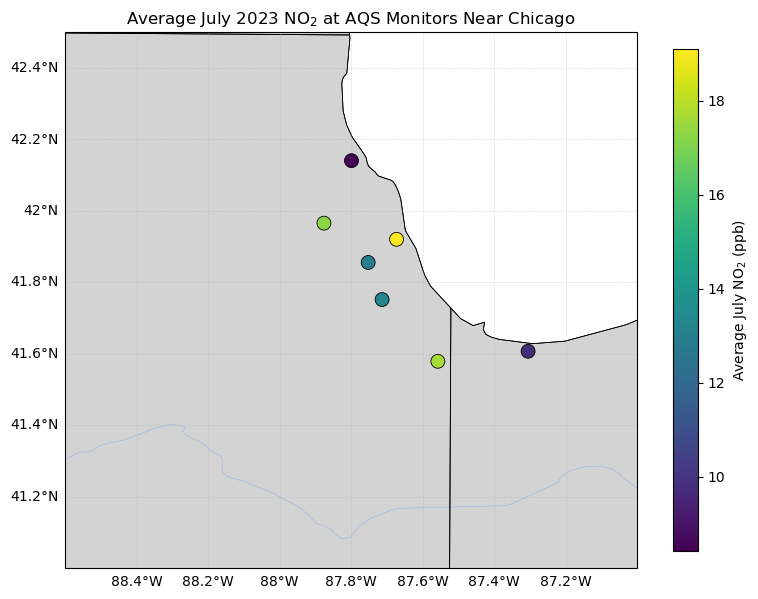

In [15]:
# Now lets make it a lil fancier

fig = plt.figure(figsize=(8, 7))

# PlateCarree is the standard projection for lon/lat data.
ax = plt.axes(projection=ccrs.PlateCarree())

# Set the map extent to the Chicago-area box.
# The order is [west, east, south, north].
ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# Add some basic map features.
# These make it easier to see where the monitors are spatially. 
# You don't need all of these, I usually prefer just STATES and LAKE personally
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.LAKES, facecolor="white", edgecolor="black", linewidth=0.5)
ax.add_feature(cfeature.RIVERS, linewidth=0.4)
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
ax.add_feature(cfeature.STATES, linewidth=0.6)

# Plot the monitor locations.
# The transform tells Cartopy that the points are in longitude/latitude.
sc = ax.scatter(
    monitor_july_mean["Longitude"],
    monitor_july_mean["Latitude"],
    c=monitor_july_mean["mean_no2_july"],
    s=100,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.6,
    transform=ccrs.PlateCarree(),
    zorder=10
)

# Add gridlines with labels.
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5,
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False

# Add colorbar.
cbar = plt.colorbar(sc, ax=ax, shrink=0.75)
cbar.set_label("Average July NO$_2$ (ppb)")

ax.set_title("Average July 2023 NO$_2$ at AQS Monitors Near Chicago")

plt.tight_layout()
plt.show()

<h2> NO2 was highest at 5GMT in our other script, so lets plot the max average NO2 over the region. 

In [12]:
# Pull out the hour from the datetime column.
no2_chicago["Hour GMT"] = no2_chicago["Datetime GMT"].dt.hour

# Keep only observations from 5 GMT.
no2_5gmt = no2_chicago[
    no2_chicago["Hour GMT"] == 5
].copy()

print("Rows at 5 GMT:", len(no2_5gmt))
print("Number of monitors at 5 GMT:", no2_5gmt["monitor_id"].nunique())

# Average across all July days, but only using the 5 GMT observations.
monitor_5gmt_mean = (
    no2_5gmt
    .groupby(["monitor_id", "Latitude", "Longitude"], as_index=False)
    .agg(
        mean_no2_5gmt=("NO2_ppb", "mean"),
        n_obs_5gmt=("NO2_ppb", "count")
    )
)

display(monitor_5gmt_mean)

Rows at 5 GMT: 165
Number of monitors at 5 GMT: 7


,monitor_id,Latitude,Longitude,mean_no2_5gmt,n_obs_5gmt
0,17-031-0076,41.751400,-87.713488,22.050000,10
1,17-031-0119,41.578620,-87.557406,21.738710,31
2,17-031-0219,41.920009,-87.672995,28.305000,20
3,17-031-3103,41.965193,-87.876265,21.361290,31
4,17-031-4002,41.855243,-87.752470,22.172727,11
5,17-031-4201,42.139996,-87.799227,11.658065,31
6,18-089-0022,41.606662,-87.304943,15.532258,31


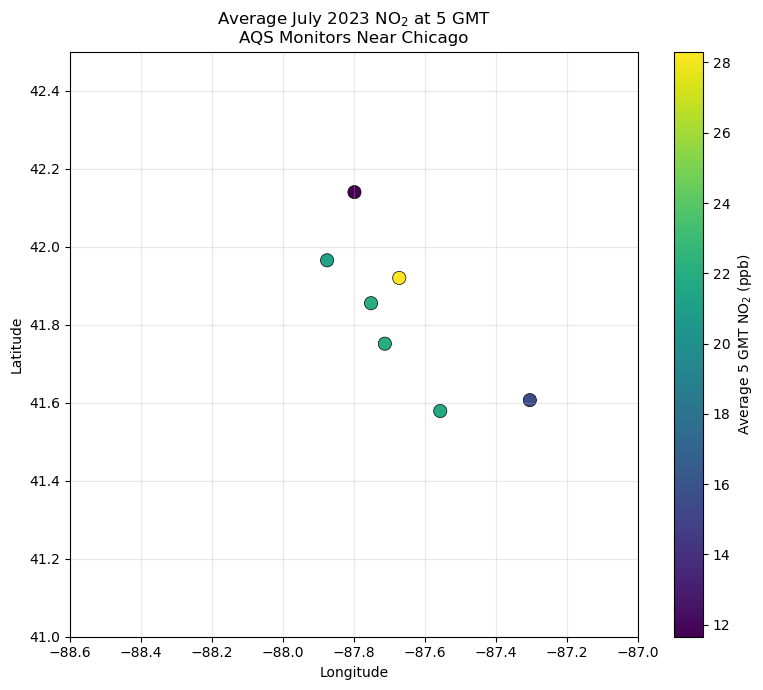

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))

sc = ax.scatter(
    monitor_5gmt_mean["Longitude"],
    monitor_5gmt_mean["Latitude"],
    c=monitor_5gmt_mean["mean_no2_5gmt"],
    s=90,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.5
)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Average 5 GMT NO$_2$ (ppb)")

ax.set_title("Average July 2023 NO$_2$ at 5 GMT\nAQS Monitors Near Chicago")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

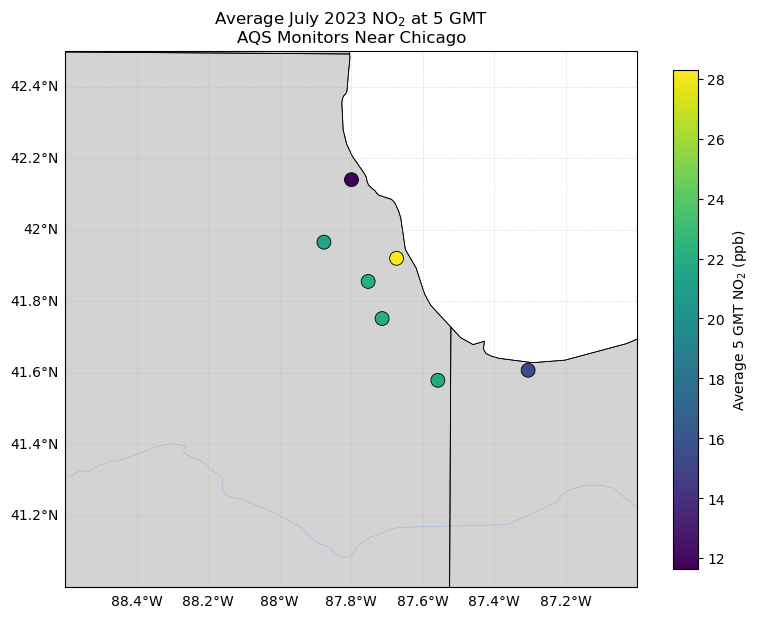

In [16]:
fig = plt.figure(figsize=(8, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.LAKES, facecolor="white", edgecolor="black", linewidth=0.5)
ax.add_feature(cfeature.RIVERS, linewidth=0.4)
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
ax.add_feature(cfeature.STATES, linewidth=0.6)

sc = ax.scatter(
    monitor_5gmt_mean["Longitude"],
    monitor_5gmt_mean["Latitude"],
    c=monitor_5gmt_mean["mean_no2_5gmt"],
    s=100,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.6,
    transform=ccrs.PlateCarree(),
    zorder=10
)

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5,
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False

cbar = plt.colorbar(sc, ax=ax, shrink=0.75)
cbar.set_label("Average 5 GMT NO$_2$ (ppb)")

ax.set_title("Average July 2023 NO$_2$ at 5 GMT\nAQS Monitors Near Chicago")

plt.tight_layout()
plt.show()